[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MusicalInformatics/miws26/blob/main/alignment_2/online_alignment_audio.ipynb)

# Online Music Alignment with Matchmaker (Audio)

> **Note.** This notebook is adapted from the notebook [`online_alignment_audio.ipynb`](https://github.com/pymatchmaker/mec2026_alignment_workshop/blob/main/online_alignment/online_alignment_audio.ipynb) of the workshop [*Music Alignment Uncovered: Representations, Algorithms and Hands-On Tools*](https://github.com/pymatchmaker/mec2026_alignment_workshop) at the Music Encoding Conference 2026. The code was originally created by Jiyun Park, and adapted for the purposes of this class.

In this notebook we align **one audio recording and the corresponding score** using [Matchmaker](https://github.com/pymatchmaker/matchmaker).

## 0. Setup

In Colab, the cell below installs [Partitura](https://github.com/CPJKU/partitura), [Matchmaker](https://github.com/pymatchmaker/matchmaker) and FluidSynth (Matchmaker uses it to render the score as audio), and gets the data from the repository. When running locally, these packages are part of the course environment. After this, we import everything we need.

In [30]:
import os

try:
    import google.colab

    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    # Install python packages
    ! pip install git+https://github.com/CPJKU/partitura.git@develop
    ! pip install "pymatchmaker>=0.4.0"

    # Install FluidSynth (Matchmaker uses it to render the score as audio)
    ! apt-get update -qq
    ! apt-get install -y -qq fluidsynth

    # To be able to access the data in the repo for this tutorial
    # (not necessary if the jupyter notebook is run locally instead of google colab)
    if not os.path.exists("./miws26"):
        !git clone https://github.com/MusicalInformatics/miws26.git

# Path to the mec-variation dataset, which contains the music example that we use
if IN_COLAB:
    MEC_VARIATION_DIR = "./miws26/alignment_1/mec-variation"
else:
    # The dataset is in the alignment_1 folder, next to this folder
    MEC_VARIATION_DIR = os.path.join(
        os.path.dirname(os.path.abspath(".")), "alignment_1", "mec-variation"
    )

In [31]:
import json
import warnings

# Silence noisy deprecation/complex warnings from matchmaker's dependencies.
warnings.filterwarnings("ignore")

import librosa
import matchmaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import partitura as pt
from IPython.display import Audio, Image, display
from pathlib import Path
from matchmaker import Matchmaker
from matchmaker.features.audio import (
    ChromagramProcessor,
    CQTProcessor,
)
from matchmaker.matchmaker import AVAILABLE_METHODS, DEFAULT_METHOD, DEFAULT_PROCESSOR
from matchmaker.utils.eval import evaluate_alignment, resolve_gt
from partitura.musicanalysis.performance_codec import get_time_maps_from_alignment

print("matchmaker", matchmaker.__version__)

# Path to the mec-variation dataset (see the setup cell above)
DATA_DIR = Path(MEC_VARIATION_DIR)
SCORE_FILE = DATA_DIR / "scores/musicxml/short.musicxml"
AUDIO_FILE = DATA_DIR / "performances/wav/short1.wav"
MIDI_FILE = DATA_DIR / "performances/midi/short1.mid"
MATCH_FILE = DATA_DIR / "alignments/match/short1.match"
SNIPPET_FILE = DATA_DIR / "performances/wav/snippet.wav"
PREVIEW_IMAGE = DATA_DIR / "scores/simple_mozart_first_two_measures.png"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

perf, alignment, score = pt.load_match(filename=str(MATCH_FILE), create_score=True)
snote_array = score.note_array()
_, stime_to_ptime_map = get_time_maps_from_alignment(
    perf.note_array(), snote_array, alignment, onset_aggregation_fun=np.min,
)
NOTE_ANNOTATIONS = stime_to_ptime_map(np.unique(snote_array["onset_beat"]))

print("Data directory:", DATA_DIR.resolve())
for path in [SCORE_FILE, AUDIO_FILE, MIDI_FILE, MATCH_FILE, SNIPPET_FILE, PREVIEW_IMAGE]:
    print(path.name, "ok" if path.exists() else "missing")
print(f"NOTE_ANNOTATIONS: {len(NOTE_ANNOTATIONS)} entries, {NOTE_ANNOTATIONS.min():.3f}s ~ {NOTE_ANNOTATIONS.max():.3f}s")

matchmaker 0.4.0
Data directory: /Users/jiyun/workspace/miws26/alignment_1/mec-variation
short.musicxml ok
short1.wav ok
short1.mid ok
short1.match ok
snippet.wav ok
simple_mozart_first_two_measures.png ok
NOTE_ANNOTATIONS: 167 entries, 0.023s ~ 22.270s


The recording below is the audio we will align against the score throughout the rest of this notebook (`short1.wav`, a take of the first 24 measures of Mozart K.265 var. 1). Every method we run from here on uses this same file as the performance input.

In [32]:
display(Audio(filename=str(AUDIO_FILE)))

## 1. Difference between online vs. offline alignment

**Offline alignment** receives the complete performance before it computes the alignment. It can revise earlier decisions because it can see the future.

**Online alignment** receives a stream of observations. At each audio frame or MIDI event, it must estimate the current score position using only the past and present. The next estimate may step back to an earlier score position, but each estimate, once emitted, is final. Past outputs cannot be revised.

Technical constraints:

- Causality: no access to future observations.
- Latency: real-time systems must finish the computation within single frame budget.

Online-specific challenges (vs offline)

- Ambiguity: repeated or harmonically similar passages can look alike locally.
- Drift & no recovery: locally-confused frames can't be revised, so errors compound over long pieces.
- Abrupt tempo changes: hard to catch up since a global cost search (which offline DTW would use) is not available.
- Noisy input: even during musically silent passages, the audio signal is not literally zero. Microphone hiss, room tone, breath, and non-instrument sounds all leak in and can confuse the feature stream.

Audio-specific challenges (vs MIDI)

- Polyphonic ambiguity: simultaneously-sounding notes share spectral bins, so per-frame pitch is uncertain.
- Onset uncertainty: onsets are smeared across the analysis window rather than landing on discrete event times. To compensate, audio-based score followers often design features to be onset-aware (e.g. by mixing harmonic features with a spectral-flux or onset-strength signal).
- Timbre & recording variation: instrument, microphone, room change the spectrogram; score-synthesized templates never match the performance exactly.

## 2. Audio Features

Matchmaker doesn't feed raw audio samples into the score follower. The `AudioStream` slices the source into fixed-size hops, and each hop goes through a `Processor` that returns one feature vector.

Two processors used in this workshop:

- `ChromagramProcessor` — 12-bin chroma. Default for audio, used by the Arzt OLTW method.
- `CQTProcessor` — 88-bin constant-Q transform. Used by the OuterHMM method.

Below we run these processors hop-by-hop on a short snippet and render the feature image one column at a time.

Below is the short score snippet for feature visualization, along with the audio snippet (first 2 measures).


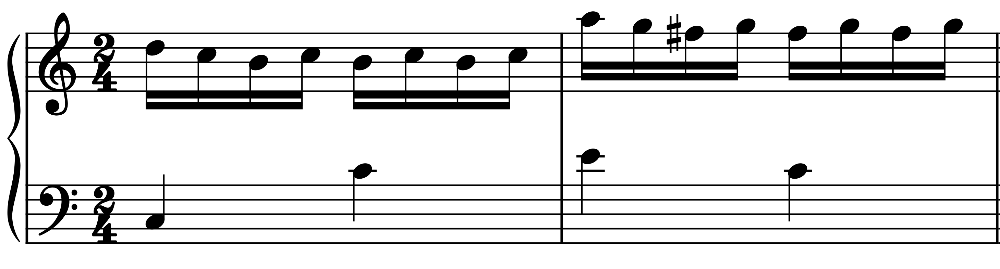

In [33]:
from IPython.display import clear_output
import matplotlib.image as mpimg

print(f"Below is the short score snippet for feature visualization, along with the audio snippet (first 2 measures).")
display(Image(filename=str(PREVIEW_IMAGE), width=700))
display(Audio(filename=str(SNIPPET_FILE)))

SCORE_IMG = mpimg.imread(str(PREVIEW_IMAGE))
SCORE_AR = SCORE_IMG.shape[1] / SCORE_IMG.shape[0]


def live_stream_processor(processor, sample_rate, hop_length, title, ylabel, yticks, yticklabels):
    audio_y, _ = librosa.load(str(SNIPPET_FILE), sr=sample_rate, mono=True)
    n_fft = getattr(processor, "n_fft", 2 * hop_length)
    features = np.array([
        np.asarray(processor((audio_y[s:s + n_fft], s / sample_rate))[0]).ravel()
        for s in range(0, len(audio_y) - n_fft + 1, hop_length)
    ]).T  # (feature_dim, n_frames)
    processor.reset()

    n_frames = features.shape[1]
    duration = n_frames * hop_length / sample_rate
    step = max(1, n_frames // 12)
    fig, (sax, ax) = plt.subplots(
        2, 1, figsize=(SCORE_AR * 2.0, 4.0), gridspec_kw={"height_ratios": [1, 1]},
    )
    sax.imshow(SCORE_IMG); sax.set_axis_off(); sax.set_title("Score (first two measures)")
    for k in range(step, n_frames + 1, step):
        ax.clear()
        ax.imshow(features[:, :k], origin="lower", aspect="auto", interpolation="nearest", vmin=0,
                  extent=[0, k * hop_length / sample_rate, 0, features.shape[0]])
        ax.set_xlim(0, duration)
        ax.set(xlabel="Performance time (s)", ylabel=ylabel, title=title)
        ax.set_yticks(yticks); ax.set_yticklabels(yticklabels); ax.grid(False)
        clear_output(wait=True); display(fig)
    plt.close(fig)
    return features

### 2-1: Chromagram

`ChromagramProcessor` collapses spectral energy into 12 pitch classes (C, C#, …, B), dropping octave information. Each call takes one hop of audio and returns a 12-dim row.

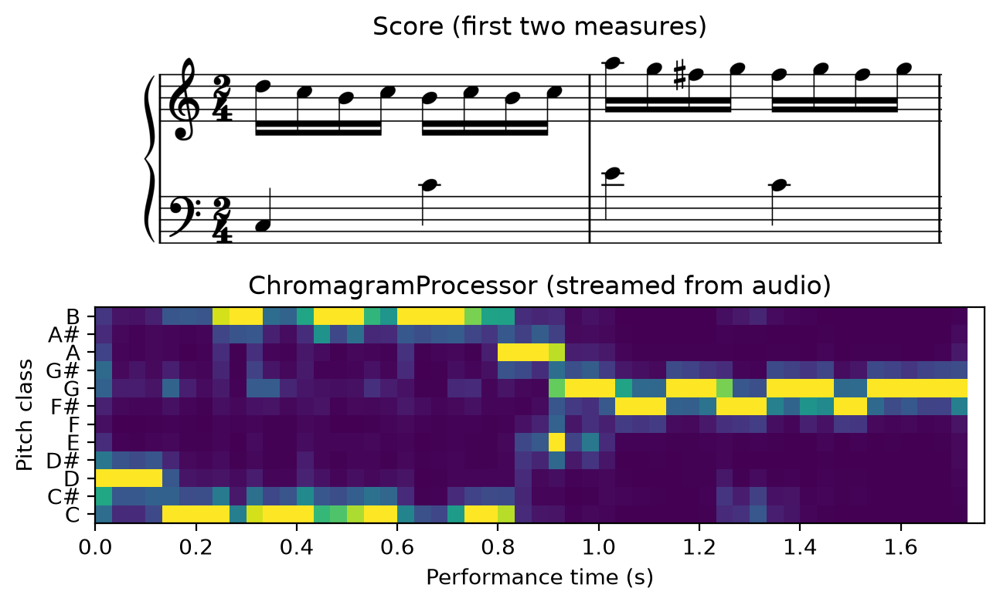

Final feature shape: (12, 53) = pitch classes x hops

Offline chroma shape: (12, 53)
Streamed (online) chroma shape: (12, 53)
Max |online - offline| over 53 overlapping frames: 3.04e-01


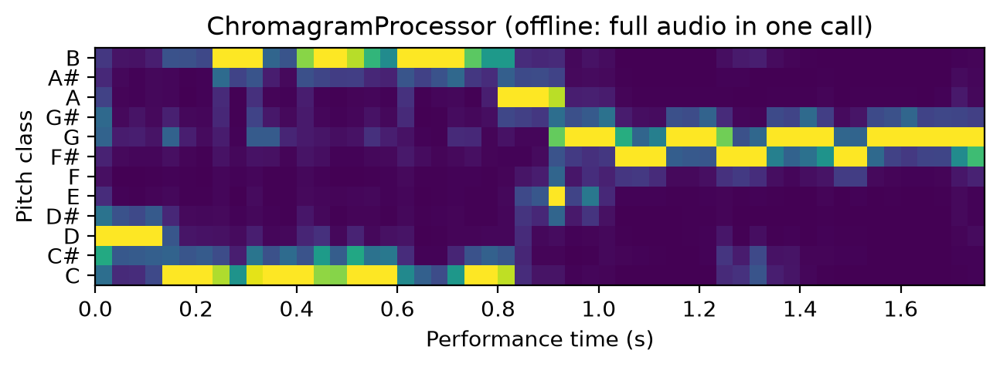

In [34]:
chroma_sr = 44100
chroma_hop = chroma_sr // 30  # 50 fps
chroma_processor = ChromagramProcessor(sample_rate=chroma_sr, hop_length=chroma_hop)
print("Processor:", chroma_processor.__class__.__name__)
print(f"  sample_rate = {chroma_sr} Hz, hop_length = {chroma_hop} samples")
print(f"  one feature row every {chroma_hop / chroma_sr * 1000:.1f} ms")

pitch_class_names = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
pitch_yticks = np.arange(12) + 0.5

chroma_buffer = live_stream_processor(
    chroma_processor, chroma_sr, chroma_hop,
    title="ChromagramProcessor (streamed from audio)",
    ylabel="Pitch class",
    yticks=pitch_yticks,
    yticklabels=pitch_class_names,
)
print(f"Final feature shape: {chroma_buffer.shape} = pitch classes x hops")

# Online vs. offline sanity check: feed the whole snippet through in one shot.
chroma_processor.reset()
full_audio, _ = librosa.load(str(SNIPPET_FILE), sr=chroma_sr, mono=True)
offline_chroma = chroma_processor((full_audio, 0.0))[0].T  # (12, n_frames)
m = min(chroma_buffer.shape[1], offline_chroma.shape[1])
print(f"\nOffline chroma shape: {offline_chroma.shape}")
print(f"Streamed (online) chroma shape: {chroma_buffer.shape}")
print(f"Max |online - offline| over {m} overlapping frames: {np.abs(chroma_buffer[:, :m] - offline_chroma[:, :m]).max():.2e}")

fig, ax = plt.subplots(figsize=(SCORE_AR * 2.0, 2.0))
ax.imshow(
    offline_chroma, origin="lower", aspect="auto", interpolation="nearest",
    extent=[0, offline_chroma.shape[1] * chroma_hop / chroma_sr, 0, 12], vmin=0,
)
ax.set(xlabel="Performance time (s)", ylabel="Pitch class",
       title="ChromagramProcessor (offline: full audio in one call)")
ax.set_yticks(pitch_yticks)
ax.set_yticklabels(pitch_class_names)
plt.show()

### 2-2: CQT (Constant-Q Transform)

`CQTProcessor` returns an 88-bin constant-Q transform per hop, one bin per piano key (A0–C8). Unlike chroma, the octave is preserved — you can read off actual notes rather than just pitch classes.

The audio `outerhmm` follower uses the related `CQTSpectralFluxProcessor`, which packs the same 88 CQT bins plus a 89th spectral-flux row used as an exit-boost signal. For visualization we use the plain CQT version since the flux value lives on a very different scale (sum over 88 bins) and would dominate a shared colormap.

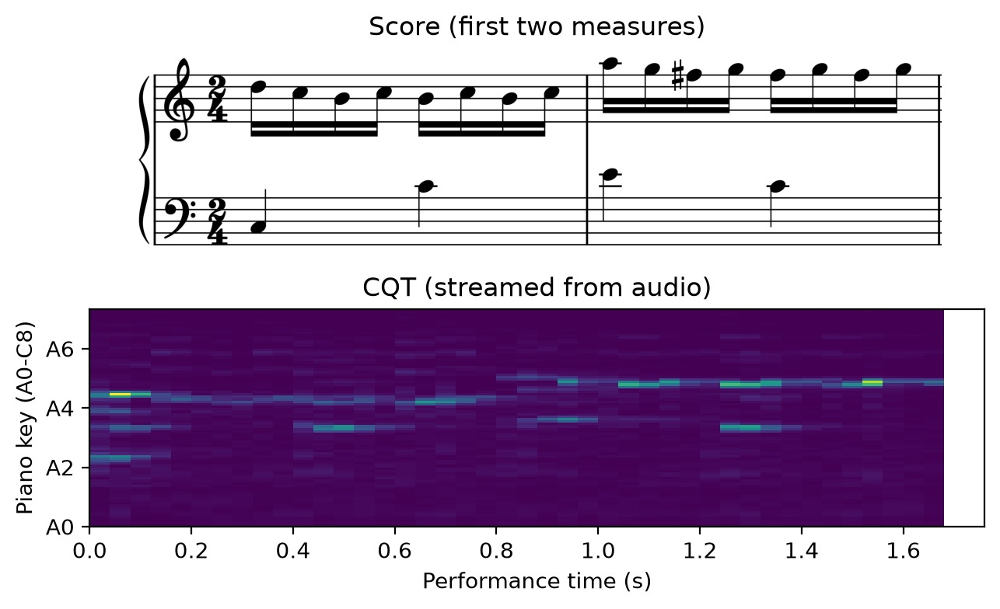

Final feature shape: (88, 44) = CQT bins x hops

Offline CQT shape: (88, 44)
Streamed (online) CQT shape: (88, 44)
Max |online - offline| over 44 overlapping frames: 1.06e+00


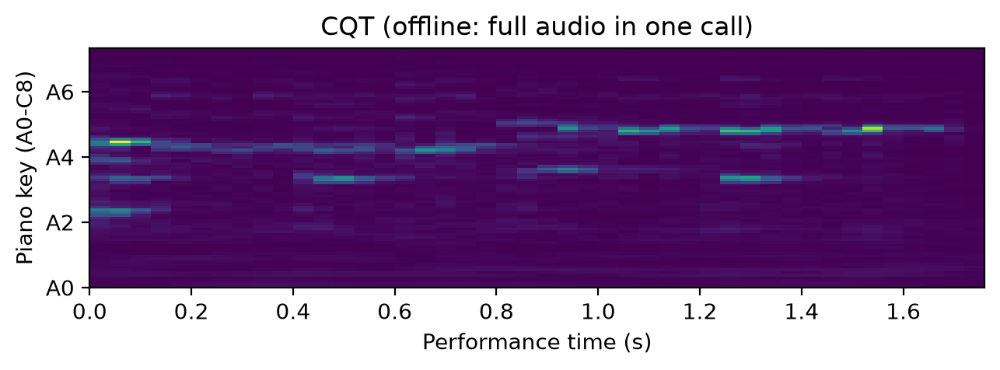

In [35]:
cqt_sr = 16000
cqt_hop = cqt_sr // 25  # 25 fps
cqt_processor = CQTProcessor(sample_rate=cqt_sr, hop_length=cqt_hop)
print("Processor:", cqt_processor.__class__.__name__)
print(f"  sample_rate = {cqt_sr} Hz, hop_length = {cqt_hop} samples")
print(f"  one feature row every {cqt_hop / cqt_sr * 1000:.1f} ms")

cqt_yticks = [0, 24, 48, 72]
cqt_yticklabels = ["A0", "A2", "A4", "A6"]

cqt_buffer = live_stream_processor(
    cqt_processor, cqt_sr, cqt_hop,
    title="CQT (streamed from audio)",
    ylabel="Piano key (A0-C8)",
    yticks=cqt_yticks,
    yticklabels=cqt_yticklabels,
)
print(f"Final feature shape: {cqt_buffer.shape} = CQT bins x hops")

# Online vs. offline sanity check.
cqt_processor.reset()
full_audio_cqt, _ = librosa.load(str(SNIPPET_FILE), sr=cqt_sr, mono=True)
offline_cqt = cqt_processor((full_audio_cqt, 0.0))[0].T  # (88, n_frames)
m = min(cqt_buffer.shape[1], offline_cqt.shape[1])
print(f"\nOffline CQT shape: {offline_cqt.shape}")
print(f"Streamed (online) CQT shape: {cqt_buffer.shape}")
print(f"Max |online - offline| over {m} overlapping frames: {np.abs(cqt_buffer[:, :m] - offline_cqt[:, :m]).max():.2e}")

fig, ax = plt.subplots(figsize=(SCORE_AR * 2.0, 2.0))
ax.imshow(
    offline_cqt, origin="lower", aspect="auto", interpolation="nearest",
    extent=[0, offline_cqt.shape[1] * cqt_hop / cqt_sr, 0, offline_cqt.shape[0]],
    vmin=0,
)
ax.set(xlabel="Performance time (s)", ylabel="Piano key (A0-C8)",
       title="CQT (offline: full audio in one call)")
ax.set_yticks(cqt_yticks)
ax.set_yticklabels(cqt_yticklabels)
plt.show()

## 3. Matchmaker overview


The Matchmaker pipeline keeps the same shape for both input types; the differences above are absorbed by the choice of `Stream` and `Processor`:

```text
input source -> Stream        -> Processor -> OnlineAlignment -> current score position
(audio/MIDI)   (file or live)   (features)   (alignment method)  (beat position)
```

For this workshop, the main object is `Matchmaker`. `Matchmaker` class is an all-in-one class that encapsulates the entire alignment process, including `Processor` and `OnlineAlignment`. We use it in **simulation mode**: the input is a recorded audio or MIDI performance file, but Matchmaker feeds it through the same streaming pipeline used for real-time score following.

The cell below quickly runs Matchmaker on our example file and yields one estimated score position (in beats) per audio frame. After the loop ends, `mm.score_follower.alignment_path` stores a `(2, T)` array:

- row 0: performance time in seconds
- row 1: estimated score beat

Then, let's run the matchmaker in the simpliest way possible.

In [36]:
mm = Matchmaker(
    score_file=SCORE_FILE,
    performance_file=AUDIO_FILE,
)

positions = []
for p in mm.run():
    print(f"Estimated score beat: {p:.3f}")
    positions.append(float(p))
    
print(f"Tracked {len(positions)} observations")
print(f"First 5 estimated score beats: {[round(p, 3) for p in positions[:5]]}")
print(f"Alignment path shape: {mm.score_follower.alignment_path.shape}")

fluidsynth: warning: SDL3 not initialized, SDL3 audio driver won't be usable. Have you called SDL_Init(SDL_INIT_AUDIO) ?


* Mock listening to stream....


  0% (0 of 167) |                        | Elapsed Time: 0:00:00 ETA:  --:--:--


Estimated score beat: 0.133
Estimated score beat: 0.133
Estimated score beat: 0.133
Estimated score beat: 0.200
Estimated score beat: 0.267
Estimated score beat: 0.400
Estimated score beat: 0.400
Estimated score beat: 0.600
Estimated score beat: 0.667
Estimated score beat: 0.667
Estimated score beat: 0.733
Estimated score beat: 0.933
Estimated score beat: 0.933
Estimated score beat: 1.000
Estimated score beat: 1.133
Estimated score beat: 1.200
Estimated score beat: 1.200
Estimated score beat: 1.200
Estimated score beat: 1.200
Estimated score beat: 1.200
Estimated score beat: 1.200
Estimated score beat: 1.400
Estimated score beat: 1.600
Estimated score beat: 1.667
Estimated score beat: 1.733
Estimated score beat: 1.800
Estimated score beat: 2.000
Estimated score beat: 2.067
Estimated score beat: 2.133
Estimated score beat: 2.267
Estimated score beat: 2.333
Estimated score beat: 2.333
Estimated score beat: 2.333
Estimated score beat: 2.467
Estimated score beat: 2.533
Estimated score beat

  8% (15 of 167) |##                     | Elapsed Time: 0:00:00 ETA:   0:00:01


...

Estimated score beat: 39.867
Estimated score beat: 39.867
Estimated score beat: 40.000
Estimated score beat: 40.067
Estimated score beat: 40.133
Estimated score beat: 40.133
Estimated score beat: 40.133
Estimated score beat: 40.133
Estimated score beat: 40.133
Estimated score beat: 40.133
Estimated score beat: 40.333
Estimated score beat: 40.533
Estimated score beat: 40.667
Estimated score beat: 40.667
Estimated score beat: 40.733
Estimated score beat: 40.800
Estimated score beat: 40.867
Estimated score beat: 40.933
Estimated score beat: 40.933
Estimated score beat: 41.000
Estimated score beat: 41.067
Estimated score beat: 41.133
Estimated score beat: 41.267
Estimated score beat: 41.467
Estimated score beat: 41.667
Estimated score beat: 41.667
Estimated score beat: 41.667
Estimated score beat: 41.667
Estimated score beat: 41.733
Estimated score beat: 41.800
Estimated score beat: 41.867
Estimated score beat: 41.933
Estimated score beat: 42.067
Estimated score beat: 42.133
Estimated scor

 95% (159 of 167) |####################  | Elapsed Time: 0:00:00 ETA:   0:00:00


Estimated score beat: 43.333
Estimated score beat: 43.400
Estimated score beat: 43.400
Estimated score beat: 43.400
Estimated score beat: 43.400
Estimated score beat: 43.400
Estimated score beat: 43.467
Estimated score beat: 43.533
Estimated score beat: 43.733
Estimated score beat: 43.800
Estimated score beat: 43.867
Estimated score beat: 44.000
Estimated score beat: 44.200
Estimated score beat: 44.200
Estimated score beat: 44.267
Estimated score beat: 44.267
Estimated score beat: 44.333
Estimated score beat: 44.400
Estimated score beat: 44.400
Estimated score beat: 44.400
Estimated score beat: 44.400
Estimated score beat: 44.533
Estimated score beat: 44.733
Estimated score beat: 44.800
Estimated score beat: 44.867
Estimated score beat: 44.867
Estimated score beat: 44.867
Estimated score beat: 45.067
Estimated score beat: 45.267
Estimated score beat: 45.400
Estimated score beat: 45.400
Estimated score beat: 45.400
Estimated score beat: 45.400
Estimated score beat: 45.400
Estimated scor

100% (167 of 167) |######################| Elapsed Time: 0:00:00 Time:  0:00:00


* Stop listening to audio stream....
* Stop listening to audio stream....
Tracked 669 observations
First 5 estimated score beats: [0.133, 0.133, 0.133, 0.2, 0.267]
Alignment path shape: (2, 669)


The cell above used the minimum required arguments: just a score and a performance file. Matchmaker filled in the defaults for `method` and `processor`, detecting the input type.

Swapping in a different alignment algorithm is as simple as adding a `method="..."` argument to the constructor. The cell below lists which methods are available for each input type.

In [37]:
print("Available methods:")
for input_type, methods in AVAILABLE_METHODS.items():
    print(f"  {input_type}: {methods}")

print("\nDefaults:")
print("  method:", DEFAULT_METHOD)
print("  processor:", DEFAULT_PROCESSOR)

Available methods:
  audio: ['arzt', 'arzt_tempo', 'arzt_multi_fold', 'dixon', 'outerhmm', 'skf', 'pfkorz']
  midi: ['arzt', 'dixon', 'hmm', 'pthmm', 'outerhmm', 'pfkorz', 'OPTM', 'OTM', 'SLT_OLTW', 'SL_OLTW']

Defaults:
  method: {'audio': 'arzt', 'midi': 'pthmm'}
  processor: {'audio': 'chroma', 'midi': 'pitch'}


### 3.1 Reading Matchmaker's score positions

Matchmaker reports the current position in **score beats**. For this Mozart example, the score positions come from Partitura's `note_array()` representation, especially the `onset_beat` field.

The unique note-onset beats become the main discrete score states used by several online followers.

Number of notes: 218
Number of unique score onset positions: 167
First 8 score positions in beats (first measure):
[0.   0.25 0.5  0.75 1.   1.25 1.5  1.75]


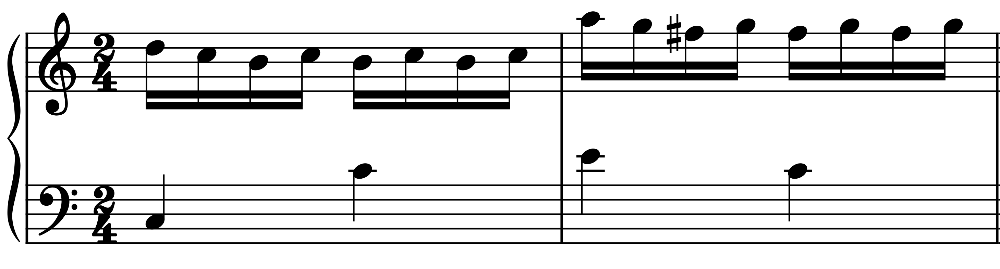

,id,pitch,onset_beat,duration_beat
0,n9,48,0.00,1.00
1,n1,74,0.00,0.25
2,n2,72,0.25,0.25
3,n3,71,0.50,0.25
4,n4,72,0.75,0.25
5,n10,60,1.00,1.00
6,n5,71,1.00,0.25
7,n6,72,1.25,0.25
8,n7,71,1.50,0.25
9,n8,72,1.75,0.25


In [38]:
score = pt.load_musicxml(str(SCORE_FILE))
score_part = score[0]
note_array = score_part.note_array()
score_positions = np.unique(note_array["onset_beat"])

print(f"Number of notes: {len(note_array)}")
print(f"Number of unique score onset positions: {len(score_positions)}")
print("First 8 score positions in beats (first measure):")
print(score_positions[:8])

display(Image(filename=str(PREVIEW_IMAGE), width=700))

pd.DataFrame(note_array[:10])[["id", "pitch", "onset_beat", "duration_beat"]]

#### Time domain vs. beat domain

A score follower connects two different time axes:

- **Time domain**: the absolute time of the performance, in seconds. This is when things actually happen (e.g., the audio frames that the follower receives).
- **Beat domain**: the time axis of the score, in beats. This is a more abstract (or "virtual") time: the score tells us that a note starts at beat 3.5, but not *when* it will be played. Matchmaker reports score positions in beats (the `onset_beat` values above); in this piece (in 2/4), one beat is a quarter note.

To convert beats into seconds, we need the **tempo**, usually in beats per minute (BPM): at a constant tempo, one beat lasts $60 / \text{BPM}$ seconds. But performers rarely keep a constant tempo, especially in classical music: they speed up, slow down and stretch individual notes. So the tempo itself changes over the piece, and the curve of these changes is the **tempo curve**.

The plot below shows both for our performance, using the ground truth alignment:

- **Left**: the score position (beats) of each onset over the performance time (seconds). At a constant tempo, this would be a straight line (dashed: the average tempo of the performance). The deviations from this line come from the tempo changes of the performer.
- **Right**: the tempo curve, i.e., the local tempo between consecutive beats, compared with the average tempo.

This is what makes score following difficult: the follower has to find the current position in the beat domain from observations in the time domain, while the mapping between both (the tempo) keeps changing.

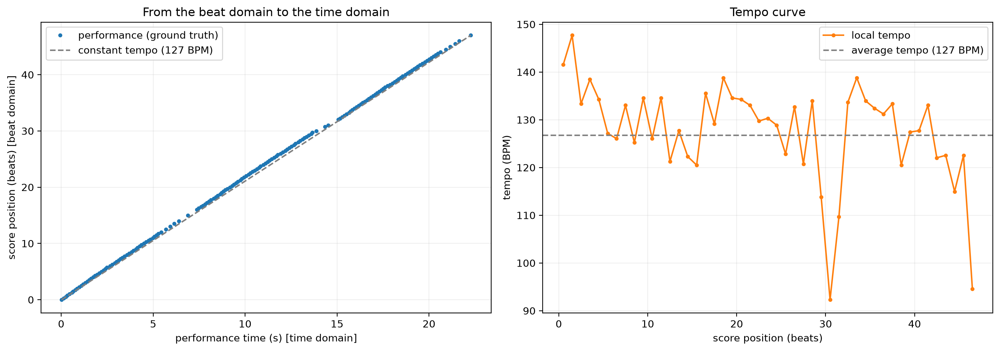

In [39]:
# The ground truth links both domains: the performance time (seconds) of each score onset (beats)
onset_beats = np.unique(snote_array["onset_beat"])
onset_times = NOTE_ANNOTATIONS

# Average tempo: number of beats / duration (in minutes)
avg_bpm = 60 * (onset_beats[-1] - onset_beats[0]) / (onset_times[-1] - onset_times[0])

# Local tempo between consecutive beats: performance time at each (integer) beat
int_beats = np.arange(np.ceil(onset_beats[0]), np.floor(onset_beats[-1]) + 1)
time_at_beat = np.interp(int_beats, onset_beats, onset_times)
local_bpm = 60 / np.diff(time_at_beat)
beat_mid = (int_beats[:-1] + int_beats[1:]) / 2

fig, (ax_map, ax_tempo) = plt.subplots(1, 2, figsize=(14, 5))

ax_map.plot(onset_times, onset_beats, ".", color="C0", label="performance (ground truth)")
constant_tempo = onset_beats[0] + (onset_times - onset_times[0]) * avg_bpm / 60
ax_map.plot(onset_times, constant_tempo, "--", color="gray", label=f"constant tempo ({avg_bpm:.0f} BPM)")
ax_map.set(xlabel="performance time (s) [time domain]", ylabel="score position (beats) [beat domain]",
           title="From the beat domain to the time domain")
ax_map.grid(alpha=0.2)
ax_map.legend()

ax_tempo.plot(beat_mid, local_bpm, "-o", color="C1", markersize=3, label="local tempo")
ax_tempo.axhline(avg_bpm, ls="--", color="gray", label=f"average tempo ({avg_bpm:.0f} BPM)")
ax_tempo.set(xlabel="score position (beats)", ylabel="tempo (BPM)", title="Tempo curve")
ax_tempo.grid(alpha=0.2)
ax_tempo.legend()

plt.tight_layout()
plt.show()

### 3.2 How do we evaluate score following?

An online score follower outputs one estimated score position (in beats) per observation. We evaluate it against the ground-truth alignment in the `.match` file of the performance, which gives, for every performed onset, its time in the performance (in seconds) and its position in the score (in beats). The notebook [`alignment_metrics.ipynb`](alignment_metrics.ipynb) explains these metrics in detail (section *Time-level metrics*); here we focus on the main points.

**Why we measure the errors in beats**

<img src="img/online_eval_beats_vs_ms.png" alt="Error in beats vs. error in ms for monotonic and non-monotonic alignment paths and ground truths" width="900"/>

The ground truth (blue) and the estimates of the follower (orange) are both curves of score position over performance time, so we could compare them in two directions:

- **(a) Error in beats (vertical)**: at the time of a ground-truth onset, we take the position that the follower had reported at that moment (the last one) and compare it with the true position: $e_b = b_{\text{true}} - b_{\text{predicted}}$. This is always well defined, since at any moment the follower has exactly one current position, and it is causal: it only uses what the follower had reported up to that moment.
- **(b) Error in ms (horizontal)**: we could instead ask *when* the follower reached the true position, and measure the time difference $\Delta t$. For this, we need to invert the path of the follower (from score position to time), which only works if the path is monotonic.
- **(c) Online paths are not necessarily monotonic**: an online follower can jump ahead, go back and correct itself, so it can reach the same score position several times ($\hat{t}_1, \hat{t}_2, \hat{t}_3$). Then the error in ms is ambiguous (which one is *the* time?), or undefined if the follower never reaches that position.
- **(d) The ground truth can be non-monotonic, too**: the performer can also go back (e.g., repeat a passage after a mistake, or restart a phrase), so the true path reaches the same score position several times ($t_1, t_2, t_3$), and so does the follower ($\hat{t}_1, \hat{t}_2, \hat{t}_3$). Then we would also have to decide which occurrence in the prediction belongs to which occurrence in the ground truth.

The error in beats is well defined in all four cases, since at each ground-truth onset time the follower has exactly one current position. Therefore, Matchmaker reports all errors in beats. To get an idea of the errors in milliseconds, we can approximate them with the average tempo of the performance (in BPM): $e_{\text{ms}} \approx e_b \cdot 60000 / \text{BPM}$ (for `mean_b`, `median_b` and `std_b`). This is only an approximation, since the local tempo changes during a performance.

**From errors to metrics**

- A positive error means that the follower is *behind* the performer, a negative error that it is *ahead*. Onsets before the first estimate of the follower count as misses.
- `mean_b`, `median_b`, `std_b`: statistics of the absolute error $|e_b|$. `skewness` and `kurtosis` describe the shape of the signed errors.
- `accuracy_<τ>b`: an onset counts as **tracked** if $|e_b| \le \tau$, and the accuracy is the fraction of all ground-truth onsets that are tracked ($\tau$ from 0.05 to 2 beats). Small tolerances measure precision; large tolerances tell us whether the follower got lost.
- `smoothness`: how smooth the estimated trajectory is (SPARC; higher, i.e., less negative, is smoother).
- `rtf`, `feature_latency_ms`, `inference_latency_ms`: whether the follower is fast enough for real time (`rtf` below 1, and latencies below the hop size).

The helper in the next section computes all these values for a finished run. After the first run (Section 4.1), we read an example result field by field, and Section 4.3 lists all the fields.

### 3.3 Evaluating a run

To evaluate a run, we compare the alignment path of the score follower with the ground truth alignment in the `.match` file of the performance. The helper below does this with Matchmaker's evaluation utilities: `resolve_gt` reads the ground truth (the performance time of each score onset), and `evaluate_alignment` computes the evaluation metrics (see the evaluation section below). It also saves the alignment path and the ground truth (as TSV files) and the metrics (as a JSON file) in `results/`.

In [40]:
def evaluate_run(mm, match_file, run_name):
    """Evaluate a finished Matchmaker run against the ground truth in a match file.

    Returns the evaluation metrics, the alignment path (performance time in seconds,
    score position in beats) and the ground truth (performance time in seconds, score
    position in beats).
    """
    # Row 0 of the alignment path is the performance time (seconds),
    # row 1 is the estimated score position (beats)
    perf_sec, score_beat = mm.score_follower.alignment_path.astype(float)

    # For MIDI input, the ground truth uses the onset times of the MIDI file that the
    # score follower received (instead of the ones in the match file)
    performance = mm.performance_file if mm.input_type == "midi" else None
    gt_perf, gt_score = resolve_gt(
        str(match_file), mm.score_part.note_array(), performance=performance
    )

    results = evaluate_alignment(score_beat, perf_sec, gt_score, gt_perf)
    # Real-time factor: processing time / performance duration
    results["rtf"] = round(mm.alignment_duration / (gt_perf.max() - gt_perf.min()), 4)
    if mm.input_type == "audio":
        # Average feature extraction and inference latencies per frame (ms)
        results.update(mm.get_latency_stats())

    # Save the alignment path, the ground truth and the metrics
    RESULTS_DIR.mkdir(exist_ok=True)
    for prefix, path in [("wp", (perf_sec, score_beat)), ("gt", (gt_perf, gt_score))]:
        np.savetxt(
            RESULTS_DIR / f"{prefix}_{run_name}.tsv",
            np.column_stack(path),
            delimiter="\t",
            header="perf_sec\tscore_beat",
            comments="",
        )
    with open(RESULTS_DIR / f"{run_name}.json", "w") as f:
        json.dump(results, f, indent=2)

    return results, perf_sec, score_beat, gt_perf, gt_score

## 4. Running audio score following with two different alignment methods

Audio methods available in Matchmaker include:

- `"dixon"`: On-line time warping score follower (Dixon, 2005)
- `"arzt"`: Step-size-constrained on-line time warping score follower (Arzt et al., 2010, 2015)
- `"outerhmm"`: Outer-product HMM score follower  (Nakamura et al., 2014)
- `"skf"`: Switching Kalman Filter with hidden tempo (Jiang et al., 2020)
- `"pfkorz"`: Particle filter score follower (Korzeniowski et al., 2014)

We will run two of these methods on our Mozart example: `"arzt"` and `"outerhmm"`, each representing a different alignment algorithm.

### 4.1 Dynamic programming

Online Time Warping (OLTW) incrementally aligns a live incoming performance to a reference sequence by updating a dynamic-programming warping path as each new audio or symbolic feature frame arrives.
Unlike an HMM-based follower, which treats score position as a hidden state and uses transition/emission probabilities, OLTW is a distance-based dynamic-programming method that directly searches for a low-cost path through the reference-performance similarity matrix in real time.

Here, the reference features are synthesized audio features from the score, using a MIDI synthesizer (FluidSynth) using piano soundfont. The performance features are chroma features extracted from the live audio.

Performance file: short1.wav, with input mode: audio
Running Matchmaker with score file (short.musicxml) and method 'arzt'...


fluidsynth: warning: SDL3 not initialized, SDL3 audio driver won't be usable. Have you called SDL_Init(SDL_INIT_AUDIO) ?


* Mock listening to stream....
* Stop listening to audio stream....
* Stop listening to audio stream....
Tracked audio observations: 669
Evaluation result:
{
  "mean_b": 0.0855,
  "median_b": 0.0667,
  "std_b": 0.0893,
  "accuracy_0.05b": 0.3892,
  "accuracy_0.1b": 0.6707,
  "accuracy_0.3b": 0.9641,
  "accuracy_0.5b": 0.988,
  "accuracy_1b": 1.0,
  "accuracy_2b": 1.0,
  "skewness": 1.4964,
  "kurtosis": 5.6994,
  "smoothness": null,
  "rtf": 0.0311,
  "feature_latency_ms": 1.0092,
  "inference_latency_ms": 0.0309
}


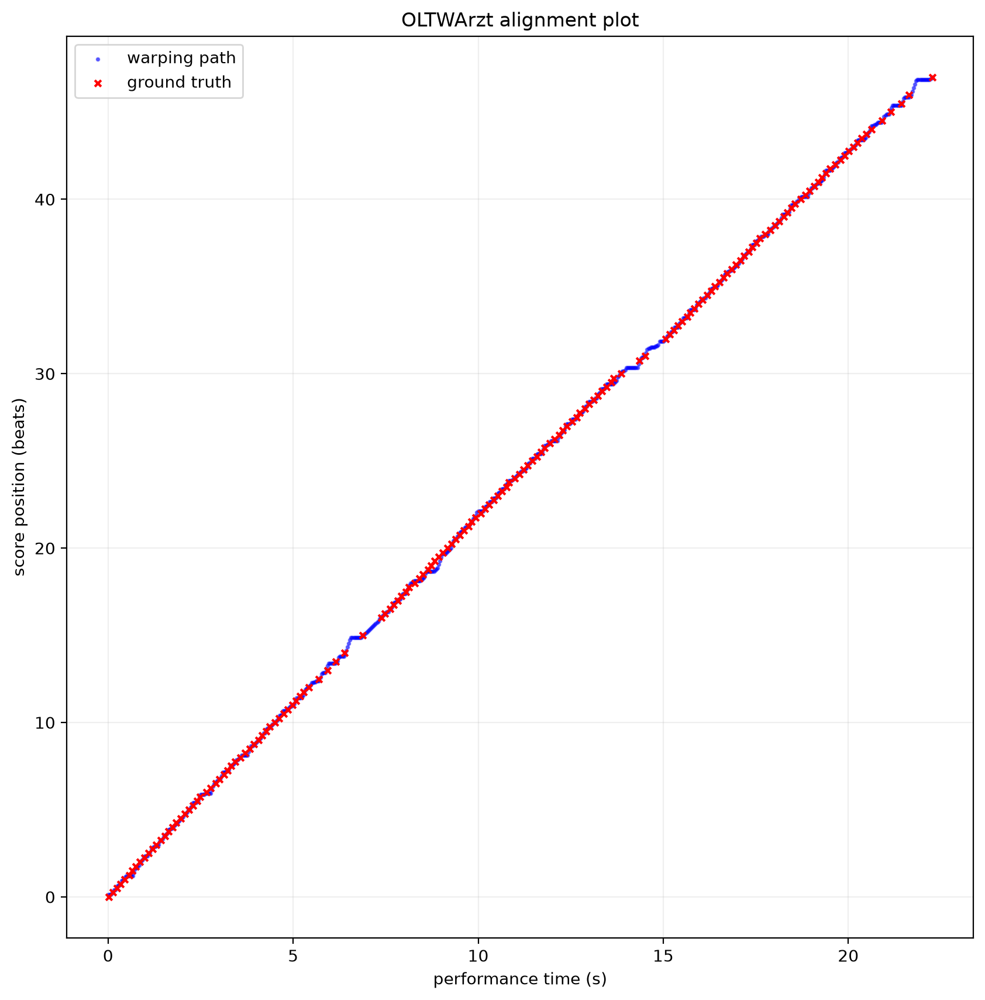

In [41]:
print(f"Performance file: {AUDIO_FILE.name}, with input mode: audio")
print(f"Running Matchmaker with score file ({SCORE_FILE.name}) and method 'arzt'...")

audio_arzt_mm = Matchmaker(
    score_file=SCORE_FILE,
    performance_file=AUDIO_FILE,
    input_type="audio",
    method="arzt",
)

audio_arzt_positions = [float(p) for p in audio_arzt_mm.run(verbose=False)]
audio_arzt_path = audio_arzt_mm.score_follower.alignment_path

print("Tracked audio observations:", len(audio_arzt_positions))

audio_arzt_eval, wp_perf, wp_score, gt_perf, gt_score = evaluate_run(
    audio_arzt_mm, MATCH_FILE, run_name="audio_arzt"
)

print("Evaluation result:")
print(json.dumps(audio_arzt_eval, indent=2))

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(wp_perf, wp_score, color="blue", s=3, alpha=0.5, label="warping path")
ax.scatter(gt_perf, gt_score, color="red", marker="x", s=15, zorder=3, label="ground truth")
ax.set(xlabel="performance time (s)", ylabel="score position (beats)", title="OLTWArzt alignment plot")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

#### How to read the evaluation result

Let's read the result of the Arzt follower above, field by field (the values below are from our run; yours may differ slightly, especially the timing values). As a reference: the score is in 2/4, so one beat is a quarter note, and the variation is mostly in sixteenth notes, which are 0.25 beats apart.

| Field | Value | How to read it |
| --- | --- | --- |
| `mean_b`, `median_b` | 0.0855, 0.0667 | On average, the estimated position is less than a tenth of a beat off, i.e., well below the distance between two consecutive sixteenth notes (0.25 beats). The median is smaller than the mean, so a few larger errors pull the mean up. |
| `std_b` | 0.0893 | The errors vary about as much as their mean, so the accuracy is not uniform across the piece. |
| `accuracy_0.05b`, `accuracy_0.1b` | 0.389, 0.671 | Only 39% of the onsets are within 1/20 beat, but two thirds are within 1/10 beat: the follower is close, but not *exactly* on the onsets. |
| `accuracy_0.3b`, `accuracy_0.5b` | 0.964, 0.988 | 96% of the onsets are within about one sixteenth note, and only 2 of the 167 onsets are more than half a beat off. |
| `accuracy_1b`, `accuracy_2b` | 1.0, 1.0 | No onset is more than one beat off: the follower never got lost. |
| `skewness` | 1.50 | The signed errors have a long tail on the positive side: when the follower is off, it is more often *behind* the performer than ahead. |
| `kurtosis` | 5.70 | Heavy tails (a normal distribution would have 0): most errors are small, with a few larger outliers. |
| `smoothness` | `None` | SPARC could not be computed: the alignment path ends 3 ms before the last ground-truth onset, so it does not cover the evaluated time span. |
| `rtf` | 0.032 | Processing takes about 3% of the duration of the performance, i.e., the follower runs about 30 times faster than real time. |
| `feature_latency_ms`, `inference_latency_ms` | 1.04, 0.03 | Each frame takes about 1 ms to process (almost all of it feature extraction), far below the hop size of 33 ms (30 frames per second). |

**From beats to milliseconds.** The errors are in beats, but we can approximate them in milliseconds with the average tempo of the performance: $e_{\text{ms}} \approx e_{\text{beats}} \cdot 60000 / \text{BPM}$. This performance has an average tempo of about 127 BPM, so one beat lasts about 473 ms. The mean error of 0.0855 beats is then about 40 ms, the median error about 32 ms, and the standard deviation about 42 ms. The cell below computes this approximation from the ground truth.

In [42]:
# Average tempo of the performance (BPM), from the first and last ground-truth onsets
avg_bpm = 60 * (gt_score.max() - gt_score.min()) / (gt_perf.max() - gt_perf.min())
ms_per_beat = 60_000 / avg_bpm
print(f"Average tempo: {avg_bpm:.1f} BPM (1 beat ≈ {ms_per_beat:.0f} ms)")

# Approximate the beat errors in milliseconds
for key in ["mean_b", "median_b", "std_b"]:
    print(f"{key}: {audio_arzt_eval[key]:.4f} beats ≈ {audio_arzt_eval[key] * ms_per_beat:.0f} ms")

Average tempo: 126.8 BPM (1 beat ≈ 473 ms)
mean_b: 0.0855 beats ≈ 40 ms
median_b: 0.0667 beats ≈ 32 ms
std_b: 0.0893 beats ≈ 42 ms


### 4.2 HMM audio input features: CQT + spectral flux

An HMM-based score follower models the current score position as a hidden state and infers it from incoming performance features using emission probabilities and transition probabilities between score positions. Compared with OLTW, it is more explicitly probabilistic: the system does not just search for a low-cost path, but maintains beliefs over possible score positions and updates them as new audio or MIDI observations arrive.

The audio `outerhmm` configuration uses `processor="cqt_spectral_flux"` for the incoming performance audio. Compared with chroma, this representation keeps a wider pitch range and adds a spectral-flux component that emphasizes frame-to-frame changes.

Performance file: short1.wav, with input mode: audio
Running Matchmaker with score file (short.musicxml) and method 'outerhmm'...
* Mock listening to stream....
* Stop listening to audio stream....* Stop listening to audio stream....

Tracked audio observations: 570
OuterHMM alignment path shape: (2, 570)
Evaluation result:
{
  "mean_b": 0.1751,
  "median_b": 0.25,
  "std_b": 0.1906,
  "accuracy_0.05b": 0.4371,
  "accuracy_0.1b": 0.4371,
  "accuracy_0.3b": 0.8982,
  "accuracy_0.5b": 0.976,
  "accuracy_1b": 1.0,
  "accuracy_2b": 1.0,
  "skewness": 1.0776,
  "kurtosis": 2.6239,
  "smoothness": -15.5371,
  "rtf": 0.183,
  "feature_latency_ms": 7.151,
  "inference_latency_ms": 0.1034
}


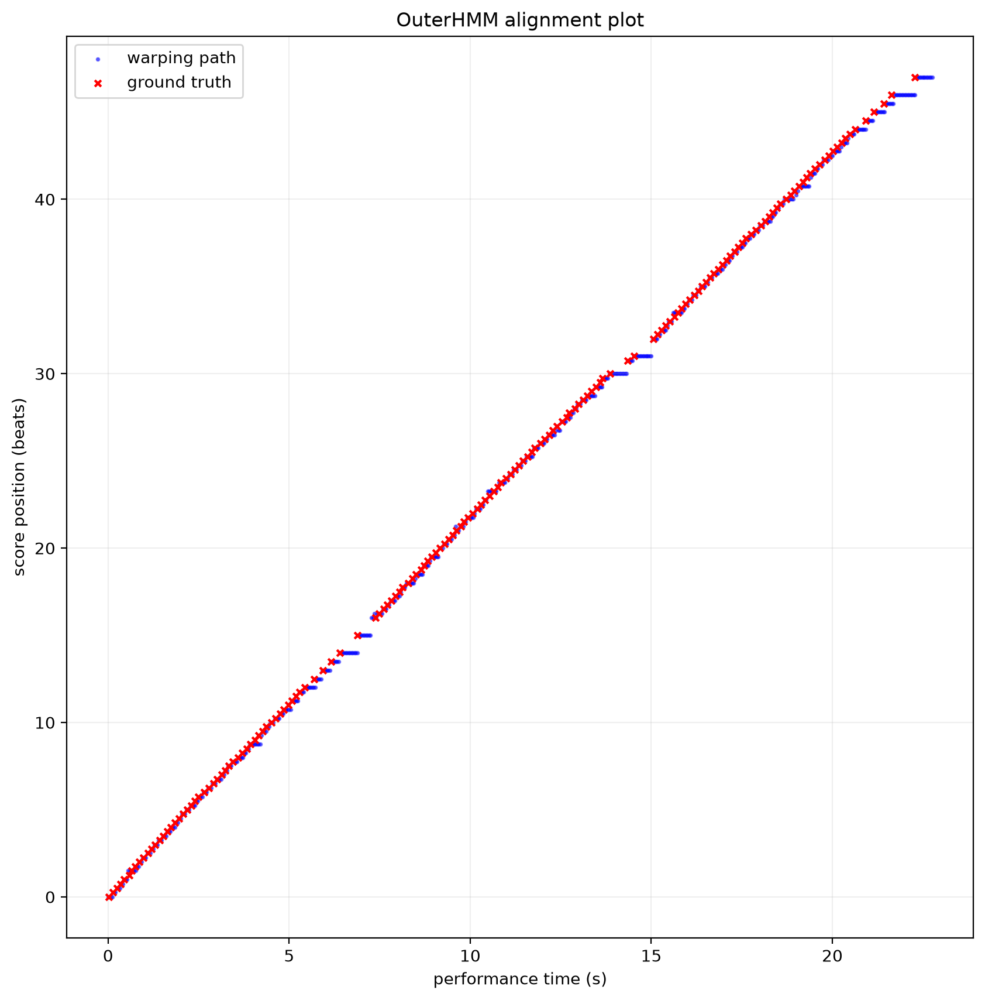

In [43]:
print(f"Performance file: {AUDIO_FILE.name}, with input mode: audio")
print(f"Running Matchmaker with score file ({SCORE_FILE.name}) and method 'outerhmm'...")

audio_outerhmm_mm = Matchmaker(
    score_file=SCORE_FILE,
    performance_file=AUDIO_FILE,
    input_type="audio",
    method="outerhmm",
)

audio_outerhmm_positions = [p for p in audio_outerhmm_mm.run(verbose=False)]
audio_outerhmm_path = audio_outerhmm_mm.score_follower.alignment_path

print("Tracked audio observations:", len(audio_outerhmm_positions))
print("OuterHMM alignment path shape:", audio_outerhmm_path.shape)

audio_outerhmm_eval, outerhmm_wp_perf, outerhmm_wp_score, gt_perf, gt_score = evaluate_run(
    audio_outerhmm_mm, MATCH_FILE, run_name="audio_outerhmm"
)

print("Evaluation result:")
print(json.dumps(audio_outerhmm_eval, indent=2))

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(outerhmm_wp_perf, outerhmm_wp_score, color="blue", s=3, alpha=0.5, label="warping path")
ax.scatter(
    gt_perf, gt_score, color="red", marker="x", s=15, zorder=3, label="ground truth"
)
ax.set(xlabel="performance time (s)", ylabel="score position (beats)", title="OuterHMM alignment plot")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

### 4.3 Audio evaluation and method comparison

The `evaluate_run` helper (Section 3.3) compares the follower's alignment path with the ground-truth annotations from the `.match` file, using Matchmaker's `evaluate_alignment`. For each ground-truth performance onset, it predicts the score position (in beats) from the alignment path and measures the error with respect to the annotated score position:

- **`mean_b`, `median_b`, `std_b` (↓)**: mean, median and standard deviation of the absolute score-position error, in beats (lower is better).
- **`accuracy_<tolerance>` (%, ↑)**: percentage of annotated onsets within the given beat-error tolerance, similar to the misalignment-rate convention used in offline sync evaluation (e.g. SyncToolbox ISMIR 2021 LBD notebook). For example, `accuracy_0.5b = 0.97` means 97 % of the onsets land within 0.5 beats of the ground truth.
- **`skewness`, `kurtosis`**: asymmetry and tail weight of the (signed) score-position error distribution.
- **`smoothness`**: how smooth the estimated score position is over time, measured with [SPARC (spectral arc length)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4674971/). Higher (less negative) values indicate smoother tracking. Smoothness depends on how positions are reported, so compare values only within the same input type (audio or MIDI).

Two extra signals matter for **online** score following, and `evaluate_run` adds them to the evaluation results:

- **`rtf`** (real-time factor): processing time / performance duration. Below 1.0 means the follower keeps up with real-time playback.
- **`feature_latency_ms`, `inference_latency_ms`**: average feature-extraction and inference time per frame in milliseconds (reported for audio input).

,method,mean_b,median_b,std_b,accuracy_0.05b,accuracy_0.1b,accuracy_0.3b,accuracy_0.5b,accuracy_1b,accuracy_2b,skewness,kurtosis,smoothness,rtf,feature_latency_ms,inference_latency_ms
0,arzt + chroma,0.0855,0.0667,0.0893,0.3892,0.6707,0.9641,0.988,1.0,1.0,1.4964,5.6994,NaN,0.0311,1.0092,0.0309
1,outerhmm + cqt_spectral_flux,0.1751,0.2500,0.1906,0.4371,0.4371,0.8982,0.976,1.0,1.0,1.0776,2.6239,-15.5371,0.1830,7.1510,0.1034


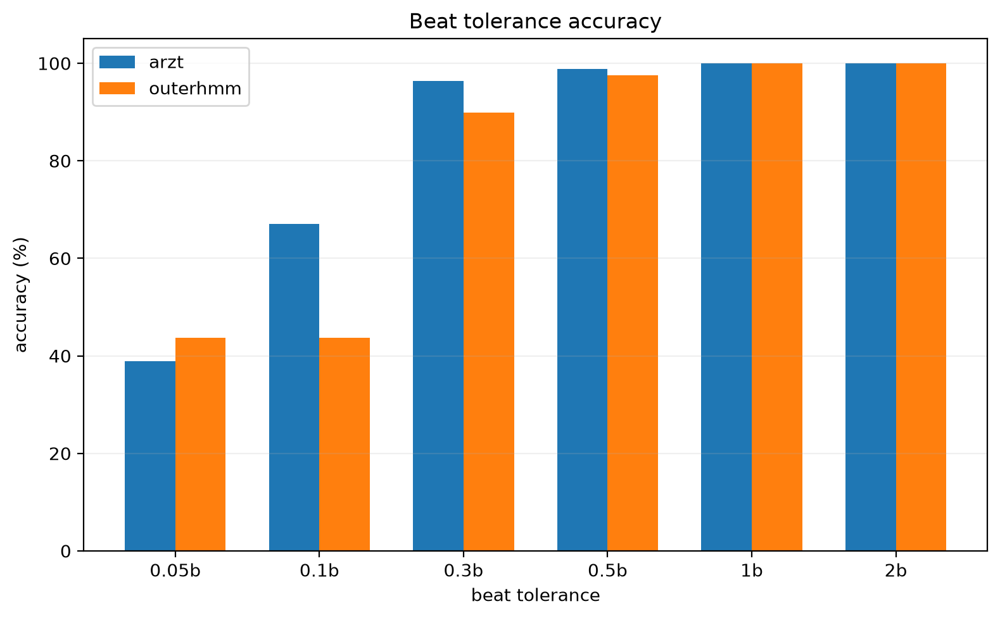

In [44]:
# Side-by-side metrics: arzt vs outerhmm.
audio_eval_df = pd.DataFrame(
    [
        {"method": "arzt + chroma", **audio_arzt_eval},
        {"method": "outerhmm + cqt_spectral_flux", **audio_outerhmm_eval},
    ]
)
with pd.option_context("display.max_columns", None, "display.width", None):
    display(audio_eval_df)

# Tolerance accuracy bar chart (y-axis in %).
beat_tols = ["0.05b", "0.1b", "0.3b", "0.5b", "1b", "2b"]
width = 0.35
x = np.arange(len(beat_tols))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, [audio_arzt_eval[f"accuracy_{t}"] * 100 for t in beat_tols], width, label="arzt", color="C0")
ax.bar(x + width / 2, [audio_outerhmm_eval[f"accuracy_{t}"] * 100 for t in beat_tols], width, label="outerhmm", color="C1")
ax.set_xticks(x)
ax.set_xticklabels(beat_tols)
ax.set(xlabel="beat tolerance", ylabel="accuracy (%)", ylim=(0, 105),
       title="Beat tolerance accuracy")
ax.legend()
ax.grid(alpha=0.2, axis="y")
plt.tight_layout()
plt.show()

Arzt/OLTW often has a smaller error because it directly optimizes a frame-level alignment path, making it very sensitive to local timing. OuterHMM is probabilistic and more state-based, which can be more robust, but its transitions and state discretization may smooth or delay the estimated position, leading to larger errors.

## 5. Tempo variation

So far we aligned `short1.wav` to the score. Let's see how the OuterHMM follower handles a slower take of the same passage: `short_slow1.wav`. The score, method, and reference features stay the same; only the performance changes.

The cell below rebuilds the ground truth annotations from the corresponding `.match` file (same procedure as in the setup cell), plots the tempo curves of the two takes, runs OuterHMM on the slow take, and compares the metrics with the original take.

Slow performance has 167 unique onsets, ends at 39.55s


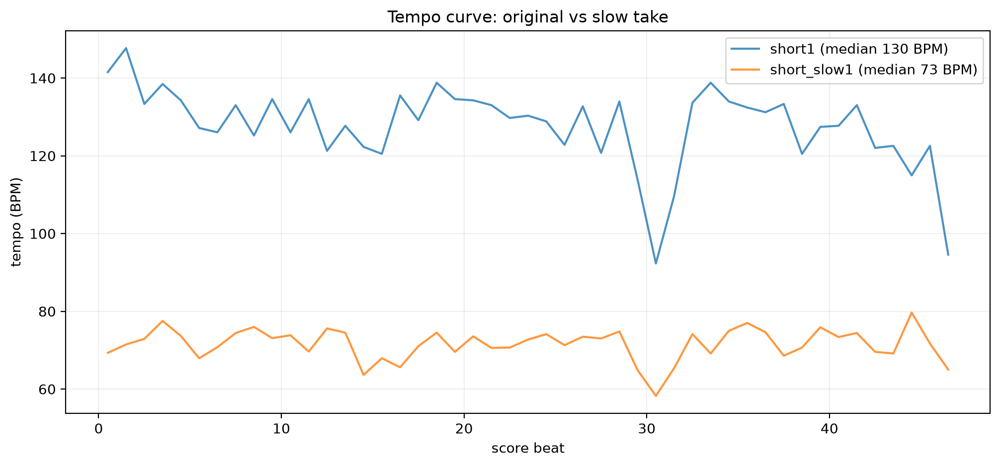

* Mock listening to stream....
* Stop listening to audio stream....* Stop listening to audio stream....



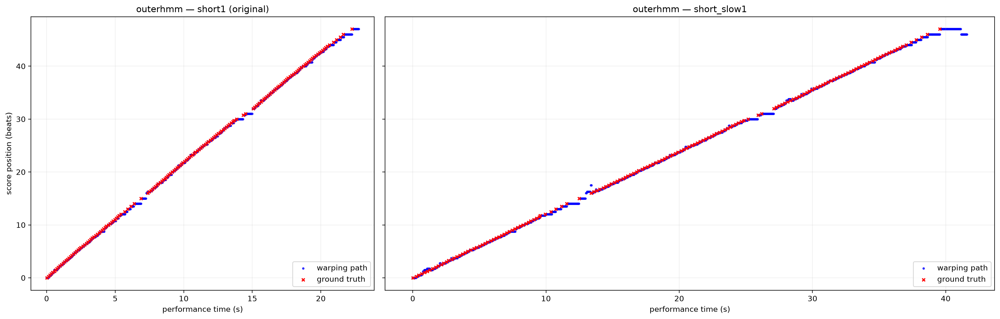

,take,mean_b (↓),"accuracy_0.1b (%, ↑)","accuracy_0.3b (%, ↑)","accuracy_0.5b (%, ↑)","accuracy_1b (%, ↑)",smoothness (↑)
0,original,0.1751,43.71,89.82,97.6,100.0,-15.5371
1,slow,0.1362,60.48,91.02,97.6,99.4,-24.7474


In [45]:
SLOW_AUDIO = DATA_DIR / "performances/wav/short_slow1.wav"
SLOW_MATCH = DATA_DIR / "alignments/match/short_slow1.match"

# Build slow-take annotations the same way as in the setup cell.
slow_perf, slow_alignment, slow_score = pt.load_match(filename=str(SLOW_MATCH), create_score=True)
slow_snote = slow_score.note_array()
_, slow_stime_to_ptime = get_time_maps_from_alignment(
    slow_perf.note_array(), slow_snote, slow_alignment, onset_aggregation_fun=np.min,
)
SLOW_NOTE_ANNOTATIONS = slow_stime_to_ptime(np.unique(slow_snote["onset_beat"]))
print(f"Slow performance has {len(SLOW_NOTE_ANNOTATIONS)} unique onsets, ends at {SLOW_NOTE_ANNOTATIONS.max():.2f}s")
display(Audio(filename=str(SLOW_AUDIO)))

# Tempo curve: local BPM between consecutive integer beats (downbeats).
# Interpolate perf time at each integer score beat so 16th-note micro-timing
# averages out.
from scipy.interpolate import interp1d
orig_beats = np.unique(snote_array["onset_beat"])
slow_beats = np.unique(slow_snote["onset_beat"])
int_beats = np.arange(int(np.ceil(orig_beats.min())), int(np.floor(orig_beats.max())) + 1)
orig_sec_at_int = interp1d(orig_beats, NOTE_ANNOTATIONS)(int_beats)
slow_sec_at_int = interp1d(slow_beats, SLOW_NOTE_ANNOTATIONS)(int_beats)
orig_bpm = 1.0 / np.diff(orig_sec_at_int) * 60
slow_bpm = 1.0 / np.diff(slow_sec_at_int) * 60
beat_mid = (int_beats[:-1] + int_beats[1:]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(beat_mid, orig_bpm, color="C0", linewidth=1.5, alpha=0.8,
        label=f"short1 (median {np.median(orig_bpm):.0f} BPM)")
ax.plot(beat_mid, slow_bpm, color="C1", linewidth=1.5, alpha=0.8,
        label=f"short_slow1 (median {np.median(slow_bpm):.0f} BPM)")
ax.set(xlabel="score beat", ylabel="tempo (BPM)", title="Tempo curve: original vs slow take")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

# Run matchmaker on the slow take.
slow_outerhmm_mm = Matchmaker(
    score_file=SCORE_FILE, performance_file=SLOW_AUDIO, input_type="audio", method="outerhmm",
)
slow_outerhmm_positions = [float(p) for p in slow_outerhmm_mm.run(verbose=False)]
slow_outerhmm_eval, slow_wp_perf, slow_wp_score, _, _ = evaluate_run(
    slow_outerhmm_mm, SLOW_MATCH, run_name="audio_outerhmm_slow"
)

# Warping-path plots: original (left) vs slow (right) for outerhmm,
# with subplot widths proportional to each take's performance duration.
orig_duration = NOTE_ANNOTATIONS.max()
slow_duration = SLOW_NOTE_ANNOTATIONS.max()
width_per_sec = 0.3

fig, axes = plt.subplots(
    1, 2, figsize=(width_per_sec * (orig_duration + slow_duration), 6), sharey=True,
    gridspec_kw={"width_ratios": [orig_duration, slow_duration]},
)
for ax, take_label, wp_x, wp_y, gt_x, gt_y in [
    (axes[0], "short1 (original)", outerhmm_wp_perf, outerhmm_wp_score, NOTE_ANNOTATIONS, orig_beats),
    (axes[1], "short_slow1", slow_wp_perf, slow_wp_score, SLOW_NOTE_ANNOTATIONS, slow_beats),
]:
    ax.scatter(wp_x, wp_y, color="blue", s=5, alpha=0.7, label="warping path")
    ax.scatter(gt_x, gt_y, color="red", marker="x", s=15, zorder=3, label="ground truth")
    ax.set(xlabel="performance time (s)", title=f"outerhmm — {take_label}")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right")
axes[0].set_ylabel("score position (beats)")
plt.tight_layout()
plt.show()

# Side-by-side metrics: original vs slow take (outerhmm).
# Arrow markers indicate direction: ↓ smaller-is-better, ↑ larger-is-better.
# Tolerance hit rates are shown as percentages.
rows = []
for take, ev in [("original", audio_outerhmm_eval), ("slow", slow_outerhmm_eval)]:
    rows.append({
        "take": take,
        "mean_b (↓)": ev["mean_b"],
        "accuracy_0.1b (%, ↑)": ev["accuracy_0.1b"] * 100,
        "accuracy_0.3b (%, ↑)": ev["accuracy_0.3b"] * 100,
        "accuracy_0.5b (%, ↑)": ev["accuracy_0.5b"] * 100,
        "accuracy_1b (%, ↑)": ev["accuracy_1b"] * 100,
        "smoothness (↑)": ev["smoothness"],
    })
display(pd.DataFrame(rows))